# Demo 2. 데이터 오염 공격과 백도어
**아주대학교 인공지능 보안 1회차 · 19:00~19:50 세션 데모**

| 단계 | 내용 | 소요 |
|---|---|---|
| 1 | 무차별 레이블 오염 (Label Flipping) — 생각보다 둔감한 모델 | 2분 |
| 2 | 표적형 오염 — 특정 클래스만 조용히 망가뜨리기 | 3분 |
| 3 | 백도어 삽입 — 트리거가 있을 때만 오작동 | 5분 |
| 4 | 탐지 · 완화 — kNN 데이터 정제, 클러스터 분석 | 4분 |

In [1]:
# 필요 패키지: numpy, scikit-learn, matplotlib (Colab/Anaconda 기본 포함)
# 로컬 환경에서 없으면: !pip install -q numpy scikit-learn matplotlib
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 110
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

X, y = load_digits(return_X_y=True); X = X / 16.0
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
rng = np.random.default_rng(42)

def make_model(): return MLPClassifier(hidden_layer_sizes=(64,), max_iter=800, random_state=0)
clean_model = make_model().fit(Xtr, ytr)
print(f"Clean model accuracy: {clean_model.score(Xte, yte):.1%}")

Clean model accuracy: 97.8%


## 1. 무차별(Untargeted) 레이블 오염
학습 데이터의 일부 레이블을 무작위로 바꿉니다. **질문**: 30%를 오염시키면 정확도는 몇 %가 될까요?

poison rate   0%  ->  test accuracy 97.0%
poison rate  10%  ->  test accuracy 95.6%


poison rate  20%  ->  test accuracy 93.0%


poison rate  30%  ->  test accuracy 94.3%
poison rate  40%  ->  test accuracy 90.0%


poison rate  50%  ->  test accuracy 89.8%


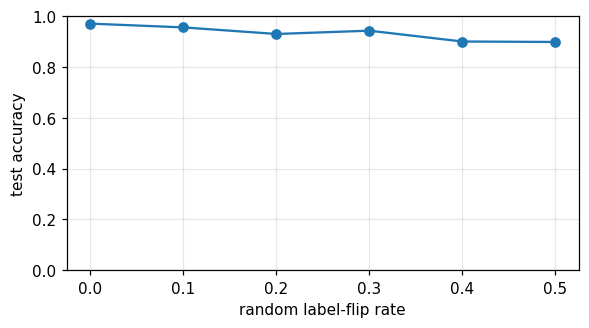

In [2]:
rates = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
accs = []
for r in rates:
    yf = ytr.copy(); k = int(r * len(ytr)); i = rng.choice(len(ytr), k, replace=False)
    yf[i] = rng.integers(0, 10, k)
    accs.append(LogisticRegression(max_iter=2000).fit(Xtr, yf).score(Xte, yte))
    print(f"poison rate {r:>4.0%}  ->  test accuracy {accs[-1]:.1%}")
plt.figure(figsize=(6, 3)); plt.plot(rates, accs, "o-"); plt.ylim(0, 1); plt.grid(alpha=.3)
plt.xlabel("random label-flip rate"); plt.ylabel("test accuracy"); plt.show()

> **강사 포인트**: 무작위 오염은 노이즈처럼 평균화되어 영향이 작고, 정확도 하락이 눈에 띄어 **탐지되기도 쉽습니다.**
> 실제 공격자는 **표적형**·**백도어**처럼 전체 정확도는 유지하면서 원하는 곳만 망가뜨립니다.

## 2. 표적형(Targeted) 데이터 오염
시나리오: 공격자는 **“7”을 “1”로 오분류**시키고 싶다. 학습 데이터 중 7 이미지 일부의 레이블만 1로 바꾼다.
(예: 신호등 인식에서 특정 표지판만, 스팸 필터에서 특정 발신자만)

Flipped 50 of 1257 training labels (4.0% of data)


Overall accuracy : clean 97.8%  vs poisoned 94.8%
Accuracy on '7'  : clean 98.1%  vs poisoned 74.1%
'7' predicted as '1': 25.9%


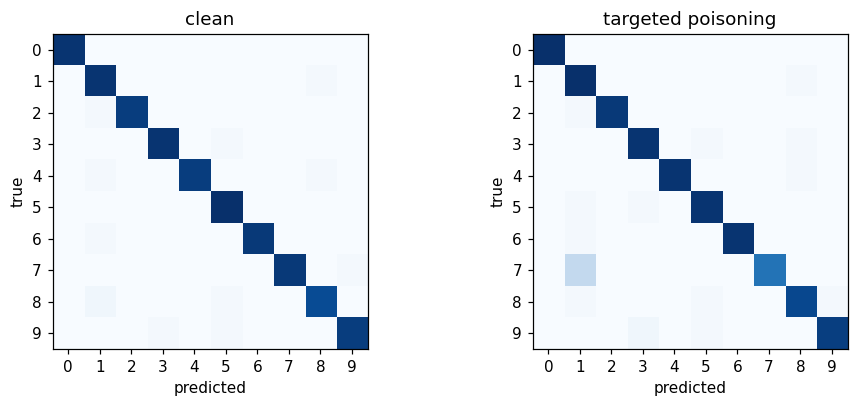

In [3]:
SRC, DST, FRAC = 7, 1, 0.4
rng = np.random.default_rng(7)
yt = ytr.copy(); src_idx = np.where(ytr == SRC)[0]
flip = rng.choice(src_idx, int(FRAC * len(src_idx)), replace=False); yt[flip] = DST
print(f"Flipped {len(flip)} of {len(ytr)} training labels ({len(flip)/len(ytr):.1%} of data)")

tgt_model = make_model().fit(Xtr, yt)
m7 = yte == SRC
print(f"Overall accuracy : clean {clean_model.score(Xte, yte):.1%}  vs poisoned {tgt_model.score(Xte, yte):.1%}")
print(f"Accuracy on '7'  : clean {clean_model.score(Xte[m7], yte[m7]):.1%}  vs poisoned {tgt_model.score(Xte[m7], yte[m7]):.1%}")
print(f"'7' predicted as '1': {(tgt_model.predict(Xte[m7]) == DST).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, m, t in [(ax[0], clean_model, "clean"), (ax[1], tgt_model, "targeted poisoning")]:
    a.imshow(confusion_matrix(yte, m.predict(Xte)), cmap="Blues"); a.set_title(t)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_xticks(range(10)); a.set_yticks(range(10))
plt.tight_layout(); plt.show()

## 3. 백도어(Backdoor) 공격 — BadNets 방식
1. 학습 데이터 일부(숫자 0 이외)에 **오른쪽 아래 2×2 흰 점(트리거)** 을 붙이고 레이블을 **0**으로 변경
2. 정상 입력에서는 정상 동작 → **일반적인 정확도 검증으로 발견 불가**
3. 트리거가 붙은 입력은 무엇이든 0으로 분류 (공격 성공률 = ASR)

In [4]:
TARGET = 0
def add_trigger(X):
    X = X.copy().reshape(-1, 8, 8); X[:, 6:8, 6:8] = 1.0; return X.reshape(-1, 64)

def backdoor_experiment(rate):
    cand = np.where(ytr != TARGET)[0]
    pidx = rng.choice(cand, int(rate * len(ytr)), replace=False)
    Xp = np.vstack([Xtr, add_trigger(Xtr[pidx])]); yp = np.hstack([ytr, np.full(len(pidx), TARGET)])
    m = make_model().fit(Xp, yp)
    nt = yte != TARGET
    return m, Xp, yp, len(pidx), m.score(Xte, yte), (m.predict(add_trigger(Xte[nt])) == TARGET).mean()

print(f"{'poison rate':<12}{'#samples':>9}{'clean acc':>11}{'ASR':>8}")
for r in [0.01, 0.03, 0.05]:
    *_, n, ca, asr = backdoor_experiment(r)
    print(f"{r:<12.1%}{n:>9}{ca:>11.1%}{asr:>8.1%}")

poison rate  #samples  clean acc     ASR


1.0%               12      97.4%   84.4%


3.0%               37      97.4%   95.7%


5.0%               62      97.6%   97.7%


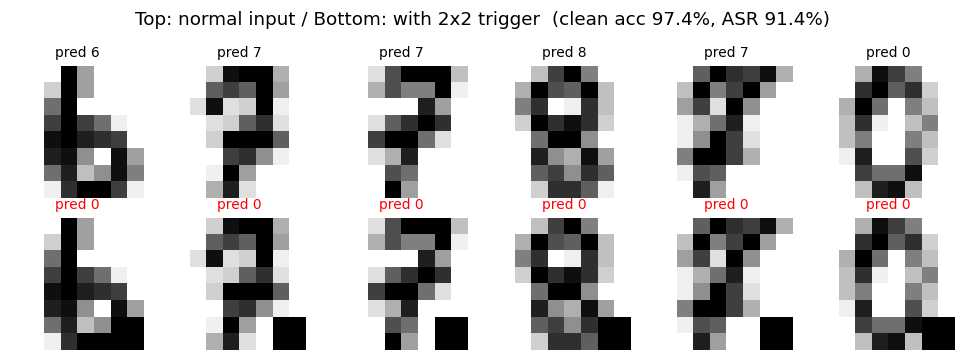

In [5]:
bd_model, Xp, yp, n_poison, ca, asr = backdoor_experiment(0.03)
sample = Xte[[3, 10, 20, 30, 40, 50]]
fig, ax = plt.subplots(2, 6, figsize=(9, 3.3))
for j, s in enumerate(sample):
    for r, img in enumerate([s, add_trigger(s[None])[0]]):
        ax[r, j].imshow(img.reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[r, j].axis("off")
        p = bd_model.predict(img[None])[0]
        ax[r, j].set_title(f"pred {p}", color="red" if (r == 1 and p == TARGET) else "black", fontsize=9)
plt.suptitle(f"Top: normal input / Bottom: with 2x2 trigger  (clean acc {ca:.1%}, ASR {asr:.1%})")
plt.tight_layout(); plt.show()

## 4. 탐지 및 완화
### ① kNN 기반 데이터 정제 (레이블 일관성 검사)
“이웃 대부분과 레이블이 다른 샘플”을 의심 데이터로 표시 → 레이블 오염(표적형) 탐지에 효과적

In [6]:
from sklearn.neighbors import NearestNeighbors
def knn_suspects(X, y, k=10, thr=0.5):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X)
    _, ind = nn.kneighbors(X)
    agree = (y[ind[:, 1:]] == y[:, None]).mean(1)
    return np.where(agree < thr)[0]

sus = knn_suspects(Xtr, yt)
tp = np.isin(sus, flip).sum()
print(f"Flagged {len(sus)} samples | true poisoned among flagged: {tp}/{len(flip)} (recall {tp/len(flip):.0%}, precision {tp/len(sus):.0%})")
keep = np.setdiff1d(np.arange(len(yt)), sus)
fixed = make_model().fit(Xtr[keep], yt[keep])
print(f"Accuracy on '7' after sanitization: {fixed.score(Xte[m7], yte[m7]):.1%}  (poisoned: {tgt_model.score(Xte[m7], yte[m7]):.1%})")

Flagged 63 samples | true poisoned among flagged: 29/50 (recall 58%, precision 46%)


Accuracy on '7' after sanitization: 79.6%  (poisoned: 74.1%)


> **강사 포인트**: 정제로 상당 부분 회복되지만 완벽하지 않습니다. 공격자가 해당 클래스의 **과반**을 오염시키면 “이웃 다수결” 자체가 오염되어 탐지가 실패합니다 → `FRAC=0.6`으로 바꿔 재실행해 보세요.

### ② 클래스 내부 클러스터 분석 (Activation Clustering 아이디어)
백도어 샘플은 “레이블은 0인데 실제 모양은 다른 숫자 + 트리거” → **0 클래스 내부에 이질적인 군집**을 형성
(원 논문은 은닉층 활성값을 쓰지만, 여기서는 은닉층 활성값 + PCA + KMeans(k=2)로 단순화)

class 0: 161 samples, poisoned 37
small cluster size 37, of which poisoned 37


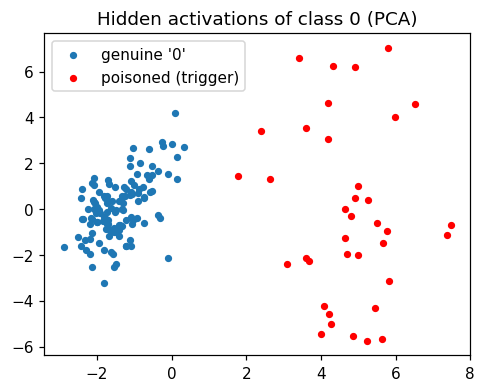

In [7]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
cls = np.where(yp == TARGET)[0]
is_poison = cls >= len(Xtr)                                   # 뒤에 붙인 샘플이 오염 데이터
H = np.maximum(0, Xp[cls] @ bd_model.coefs_[0] + bd_model.intercepts_[0])   # 은닉층 활성값(ReLU)
Z = PCA(2, random_state=0).fit_transform(H)
lab = KMeans(2, n_init=10, random_state=0).fit_predict(Z)
small = np.argmin(np.bincount(lab))
print(f"class {TARGET}: {len(cls)} samples, poisoned {is_poison.sum()}")
print(f"small cluster size {np.sum(lab == small)}, of which poisoned {np.sum(is_poison[lab == small])}")
plt.figure(figsize=(5, 3.8))
plt.scatter(*Z[~is_poison].T, s=14, label="genuine '0'"); plt.scatter(*Z[is_poison].T, s=14, c="red", label="poisoned (trigger)")
plt.legend(); plt.title(f"Hidden activations of class {TARGET} (PCA)"); plt.show()

## 정리 (슬라이드로 복귀)
| 공격 | 전체 정확도 | 피해 | 탐지 난이도 |
|---|---|---|---|
| 무차별 오염 | 하락 (눈에 띔) | 전반적 성능 저하 | 낮음 |
| 표적형 오염 | 거의 유지 | 특정 클래스만 실패 | 중간 |
| 백도어 | **유지** | 트리거 입력만 공격자 의도대로 | **높음** |

**핵심 메시지**: 정확도 검증만으로는 백도어를 찾을 수 없다 → 데이터 출처 관리(Provenance), 무결성 검증(해시·서명), 접근 통제, 데이터 정제, 모델 행위 모니터링이 함께 필요